# IEEE-CIS Transaction Fraud Analytics

Audit the labeled training data, profile fraud by segment, and export a transaction-level dataset for Power BI.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = next((parent / "Dataset" for parent in (Path.cwd(), *Path.cwd().parents)
                 if (parent / "Dataset" / "train_transaction.csv").is_file()), None)
if DATA_DIR is None or not (DATA_DIR / "train_identity.csv").is_file():
    raise FileNotFoundError("Place both training CSVs in the project Dataset folder.")
transactions = pd.read_csv(
    DATA_DIR / "train_transaction.csv",
    usecols=["TransactionID", "isFraud", "TransactionDT", "TransactionAmt", "ProductCD", "card4"],
)
identity = pd.read_csv(DATA_DIR / "train_identity.csv", usecols=["TransactionID", "DeviceType"])
print(f"Transaction rows: {len(transactions):,}")
print(f"Identity rows: {len(identity):,}")

Transaction rows: 590,540
Identity rows: 144,233


In [2]:
print("Duplicate transaction IDs:",
      transactions["TransactionID"].duplicated().sum())

print("Missing transaction IDs:",
      transactions["TransactionID"].isna().sum())

print("\nFraud labels:")
print(transactions["isFraud"].value_counts())

print("\nFraud rate:")
print(transactions["isFraud"].mean() * 100)

print("\nTransaction amount summary:")
display(transactions["TransactionAmt"].describe())

print("\nMissing values in top 15 columns:")
display(
    transactions.isna().sum()
    .sort_values(ascending=False)
    .head(15)
)

Duplicate transaction IDs: 0
Missing transaction IDs: 0

Fraud labels:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud rate:
3.4990009144173126

Transaction amount summary:

Missing values in top 15 columns:


count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64

card4             1577
TransactionID        0
isFraud              0
TransactionDT        0
TransactionAmt       0
ProductCD            0
dtype: int64

In [3]:
df = transactions.copy()

# Basic transaction-level metrics
total_transactions = len(df)
fraud_transactions = df["isFraud"].sum()
genuine_transactions = total_transactions - fraud_transactions

fraud_rate = fraud_transactions / total_transactions * 100

total_value = df["TransactionAmt"].sum()

fraud_value = df.loc[
    df["isFraud"] == 1, "TransactionAmt"
].sum()

genuine_value = df.loc[
    df["isFraud"] == 0, "TransactionAmt"
].sum()

fraud_value_share = fraud_value / total_value * 100

avg_fraud_amount = df.loc[
    df["isFraud"] == 1, "TransactionAmt"
].mean()

avg_genuine_amount = df.loc[
    df["isFraud"] == 0, "TransactionAmt"
].mean()

print(f"Total transactions: {total_transactions:,}")
print(f"Fraud transactions: {fraud_transactions:,}")
print(f"Genuine transactions: {genuine_transactions:,}")
print(f"Fraud rate: {fraud_rate:.2f}%")
print(f"Total transaction value: {total_value:,.2f}")
print(f"Fraud transaction value: {fraud_value:,.2f}")
print(f"Fraud value share: {fraud_value_share:.2f}%")
print(f"Average fraud amount: {avg_fraud_amount:.2f}")
print(f"Average genuine amount: {avg_genuine_amount:.2f}")

Total transactions: 590,540
Fraud transactions: 20,663
Genuine transactions: 569,877
Fraud rate: 3.50%
Total transaction value: 79,738,948.73
Fraud transaction value: 3,083,844.86
Fraud value share: 3.87%
Average fraud amount: 149.24
Average genuine amount: 134.51


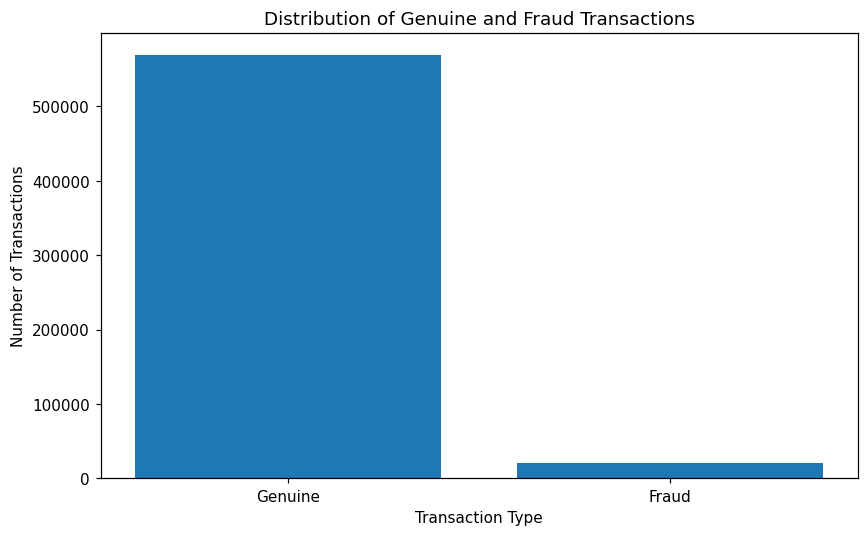

In [4]:
fraud_counts = df["isFraud"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Genuine", "Fraud"],
    fraud_counts.values
)

plt.title("Distribution of Genuine and Fraud Transactions")
plt.ylabel("Number of Transactions")
plt.xlabel("Transaction Type")

plt.tight_layout()
plt.show()

In [5]:
# Create transaction amount bands
bins = [0, 50, 100, 250, 500, float("inf")]

labels = [
    "0–50",
    "50–100",
    "100–250",
    "250–500",
    "500+"
]

df["AmountBand"] = pd.cut(
    df["TransactionAmt"],
    bins=bins,
    labels=labels,
    right=False
)

# Calculate metrics for each band
amount_analysis = (
    df.groupby("AmountBand", observed=False)
    .agg(
        Transactions=("TransactionID", "count"),
        FraudTransactions=("isFraud", "sum"),
        TotalValue=("TransactionAmt", "sum"),
        FraudValue=(
            "TransactionAmt",
            lambda x: x[df.loc[x.index, "isFraud"] == 1].sum()
        )
    )
    .reset_index()
)

amount_analysis["FraudRate"] = (
    amount_analysis["FraudTransactions"]
    / amount_analysis["Transactions"] * 100
)

amount_analysis["FraudValueShare"] = (
    amount_analysis["FraudValue"]
    / amount_analysis["TotalValue"] * 100
)

amount_analysis["ShareOfFraudValue"] = (
    amount_analysis["FraudValue"]
    / fraud_value * 100
)

display(amount_analysis.round(2))

,AmountBand,Transactions,FraudTransactions,TotalValue,FraudValue,FraudRate,FraudValueShare,ShareOfFraudValue
0,0–50,187515,7480,6015168.75,210692.05,3.99,3.50,6.83
1,50–100,160742,4618,10608248.25,320696.32,2.87,3.02,10.40
2,100–250,175923,5198,25030248.65,782372.73,2.95,3.13,25.37
3,250–500,42036,2218,14220836.45,761360.79,5.28,5.35,24.69
4,500+,24324,1149,23864446.63,1008722.97,4.72,4.23,32.71


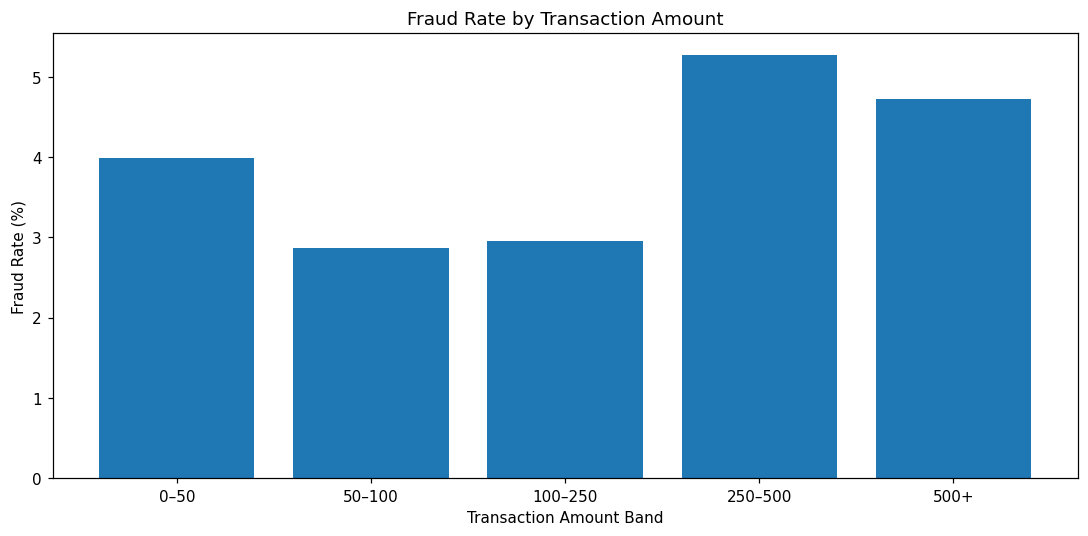

In [6]:
plt.figure(figsize=(10, 5))

plt.bar(
    amount_analysis["AmountBand"].astype(str),
    amount_analysis["FraudRate"]
)

plt.title("Fraud Rate by Transaction Amount")
plt.xlabel("Transaction Amount Band")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

In [7]:
product_analysis = (
    df.groupby("ProductCD")
    .agg(
        Transactions=("TransactionID", "count"),
        FraudTransactions=("isFraud", "sum"),
        TotalValue=("TransactionAmt", "sum"),
        FraudValue=(
            "TransactionAmt",
            lambda x: x[df.loc[x.index, "isFraud"] == 1].sum()
        )
    )
    .reset_index()
)

product_analysis["FraudRate"] = (
    product_analysis["FraudTransactions"]
    / product_analysis["Transactions"] * 100
)

product_analysis["ShareOfFraudValue"] = (
    product_analysis["FraudValue"]
    / fraud_value * 100
)

display(
    product_analysis
    .sort_values("FraudRate", ascending=False)
    .round(2)
)

,ProductCD,Transactions,FraudTransactions,TotalValue,FraudValue,FraudRate,ShareOfFraudValue
0,C,68519,8008,2937570.76,391421.40,11.69,12.69
3,S,11628,686,700813.60,43416.00,5.90,1.41
1,H,33024,1574,2416368.00,246632.00,4.77,8.00
2,R,37699,1426,6344975.00,348050.00,3.78,11.29
4,W,439670,8969,67339221.37,2054325.46,2.04,66.62


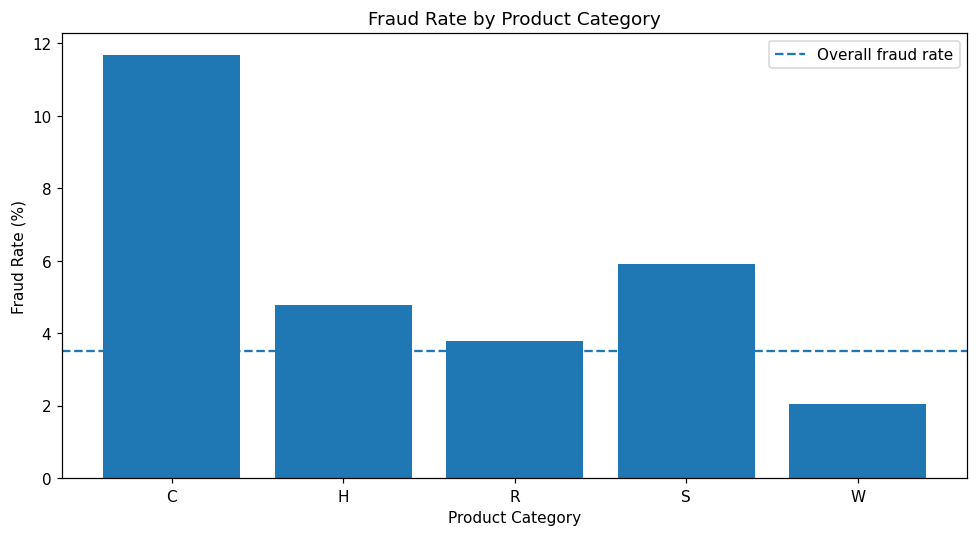

In [8]:
plt.figure(figsize=(9, 5))

plt.bar(
    product_analysis["ProductCD"],
    product_analysis["FraudRate"]
)

plt.axhline(
    fraud_rate,
    linestyle="--",
    label="Overall fraud rate"
)

plt.title("Fraud Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Fraud Rate (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
card_analysis = (
    df.groupby("card4", dropna=False)
    .agg(
        Transactions=("TransactionID", "count"),
        FraudTransactions=("isFraud", "sum"),
        TotalValue=("TransactionAmt", "sum"),
        FraudValue=(
            "TransactionAmt",
            lambda x: x[df.loc[x.index, "isFraud"] == 1].sum()
        )
    )
    .reset_index()
)

card_analysis["FraudRate"] = (
    card_analysis["FraudTransactions"]
    / card_analysis["Transactions"] * 100
)

card_analysis["ShareOfFraudValue"] = (
    card_analysis["FraudValue"]
    / fraud_value * 100
)

display(
    card_analysis
    .sort_values("FraudRate", ascending=False)
    .round(2)
)

,card4,Transactions,FraudTransactions,TotalValue,FraudValue,FraudRate,ShareOfFraudValue
1,discover,6651,514,1767506.08,182000.44,7.73,5.90
3,visa,384767,13373,51236268.46,1997705.85,3.48,64.78
2,mastercard,189217,6496,25050009.37,855739.18,3.43,27.75
0,american express,8328,239,1441219.83,42798.18,2.87,1.39
4,NaN,1577,41,243945.00,5601.21,2.60,0.18


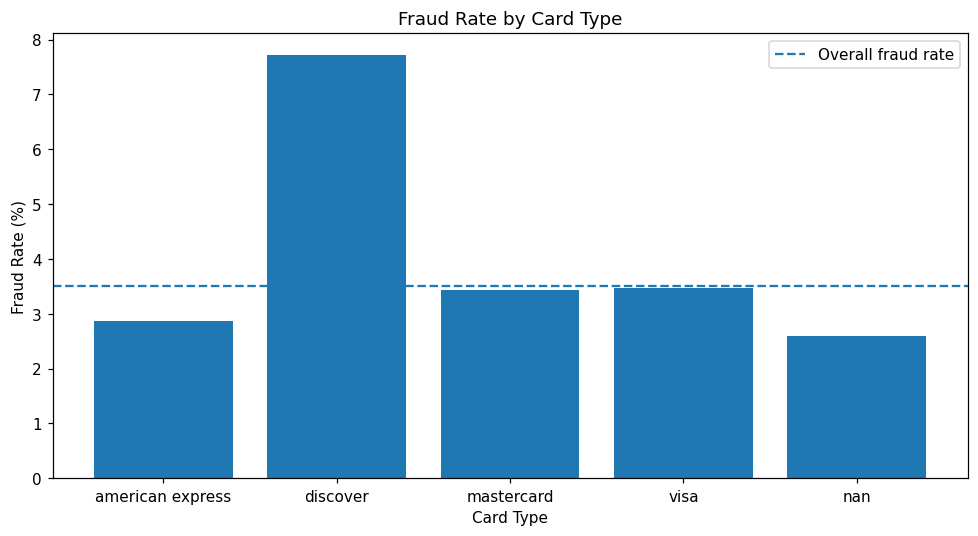

In [10]:
plt.figure(figsize=(9, 5))

plt.bar(
    card_analysis["card4"].astype(str),
    card_analysis["FraudRate"]
)

plt.axhline(
    fraud_rate,
    linestyle="--",
    label="Overall fraud rate"
)

plt.title("Fraud Rate by Card Type")
plt.xlabel("Card Type")
plt.ylabel("Fraud Rate (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
# Check whether identity records have unique transaction IDs
print(
    "Duplicate identity IDs:",
    identity["TransactionID"].duplicated().sum()
)

# Merge identity information into the transaction dataset
df_device = transactions.merge(
    identity[["TransactionID", "DeviceType"]],
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

# Label transactions with missing device information
df_device["DeviceType"] = (
    df_device["DeviceType"].fillna("Unknown")
)

print("Merged dataset shape:", df_device.shape)

Duplicate identity IDs: 0
Merged dataset shape: (590540, 7)


In [12]:
device_analysis = (
    df_device.groupby("DeviceType")
    .agg(
        Transactions=("TransactionID", "count"),
        FraudTransactions=("isFraud", "sum"),
        TotalValue=("TransactionAmt", "sum"),
        FraudValue=(
            "TransactionAmt",
            lambda x: x[
                df_device.loc[x.index, "isFraud"] == 1
            ].sum()
        )
    )
    .reset_index()
)

device_analysis["FraudRate"] = (
    device_analysis["FraudTransactions"]
    / device_analysis["Transactions"] * 100
)

device_analysis["ShareOfFraudValue"] = (
    device_analysis["FraudValue"]
    / fraud_value * 100
)

display(
    device_analysis
    .sort_values("FraudRate", ascending=False)
    .round(2)
)

,DeviceType,Transactions,FraudTransactions,TotalValue,FraudValue,FraudRate,ShareOfFraudValue
2,mobile,55645,5657,3867584.53,546427.46,10.17,17.72
1,desktop,85165,5554,7886291.45,449878.94,6.52,14.59
0,Unknown,449730,9452,67985072.76,2087538.46,2.10,67.69


In [13]:
# Convert elapsed seconds into relative days
df["TransactionDay"] = (
    (df["TransactionDT"] - df["TransactionDT"].min())
    // 86400
).astype(int)

# Group transactions by relative day
daily_analysis = (
    df.groupby("TransactionDay")
    .agg(
        Transactions=("TransactionID", "count"),
        FraudTransactions=("isFraud", "sum"),
        TotalValue=("TransactionAmt", "sum"),
        FraudValue=(
            "TransactionAmt",
            lambda x: x[df.loc[x.index, "isFraud"] == 1].sum()
        )
    )
    .reset_index()
)

daily_analysis["FraudRate"] = (
    daily_analysis["FraudTransactions"]
    / daily_analysis["Transactions"] * 100
)

daily_analysis["ShareOfFraudValue"] = (
    daily_analysis["FraudValue"]
    / fraud_value * 100
)

display(daily_analysis.head())

,TransactionDay,Transactions,FraudTransactions,TotalValue,FraudValue,FraudRate,ShareOfFraudValue
0,0,5122,112,742186.931,20337.144,2.186646,0.659474
1,1,3730,123,453400.013,15359.607,3.297587,0.498067
2,2,3241,92,348517.434,14254.337,2.838630,0.462226
3,3,4036,115,515968.997,14120.447,2.849356,0.457884
4,4,3964,127,543140.641,16692.721,3.203835,0.541296


In [14]:
# Create relative seven-day periods
df["TransactionWeek"] = (
    df["TransactionDay"] // 7
).astype(int)

weekly_analysis = (
    df.groupby("TransactionWeek")
    .agg(
        Transactions=("TransactionID", "count"),
        FraudTransactions=("isFraud", "sum"),
        FraudValue=(
            "TransactionAmt",
            lambda x: x[df.loc[x.index, "isFraud"] == 1].sum()
        )
    )
    .reset_index()
)

weekly_analysis["FraudRate"] = (
    weekly_analysis["FraudTransactions"]
    / weekly_analysis["Transactions"] * 100
)

display(weekly_analysis.round(2))

,TransactionWeek,Transactions,FraudTransactions,FraudValue,FraudRate
0,0,27596,804,115303.70,2.91
1,1,28463,717,102518.36,2.52
2,2,35701,869,103375.86,2.43
3,3,34906,724,101438.13,2.07
4,4,24539,889,121564.44,3.62
5,5,20919,803,122015.66,3.84
6,6,20564,823,104885.81,4.00
7,7,19761,862,118201.74,4.36
8,8,21432,927,127460.33,4.33
9,9,22534,996,134119.43,4.42


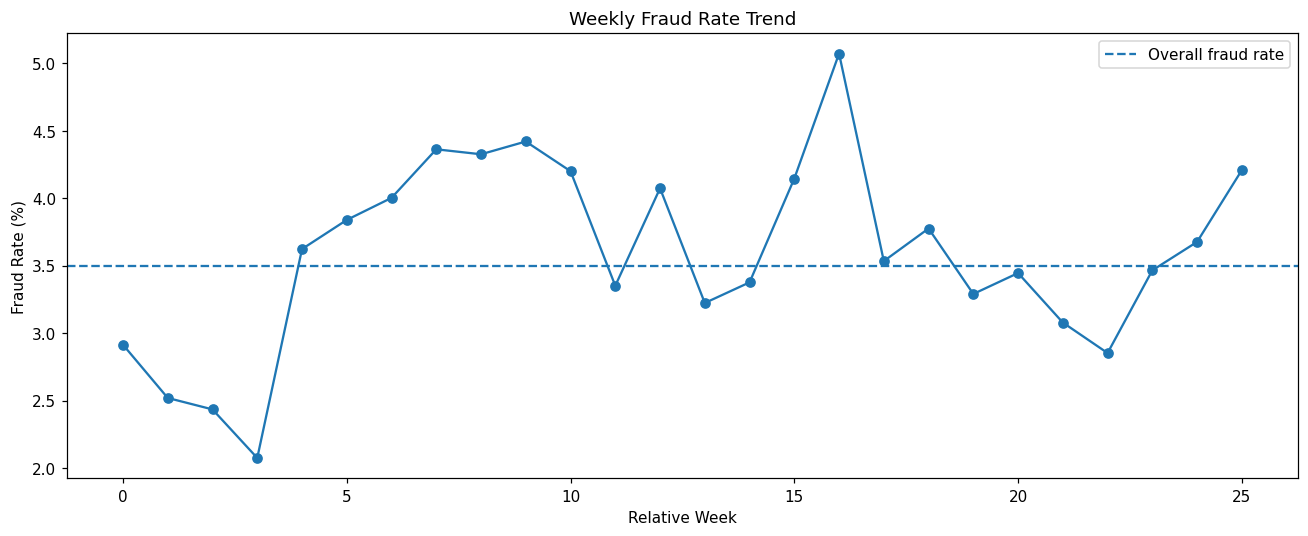

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(
    weekly_analysis["TransactionWeek"],
    weekly_analysis["FraudRate"],
    marker="o"
)

plt.axhline(
    fraud_rate,
    linestyle="--",
    label="Overall fraud rate"
)

plt.title("Weekly Fraud Rate Trend")
plt.xlabel("Relative Week")
plt.ylabel("Fraud Rate (%)")
plt.legend()

plt.tight_layout()
plt.show()

## Validate and export the Power BI dataset

In [16]:
# Validate the merged transaction dataset

print("Original transaction rows:", len(transactions))
print("Merged transaction rows:", len(df_device))

print(
    "Duplicate transaction IDs:",
    df_device["TransactionID"].duplicated().sum()
)

print(
    "Missing transaction IDs:",
    df_device["TransactionID"].isna().sum()
)

print(
    "Duplicate identity IDs:",
    identity["TransactionID"].duplicated().sum()
)

# Check whether fraud labels are valid
print("\nFraud label distribution:")
print(df_device["isFraud"].value_counts(dropna=False))

# Check critical field missingness
critical_columns = [
    "TransactionID",
    "isFraud",
    "TransactionDT",
    "TransactionAmt",
    "ProductCD",
    "card4",
    "DeviceType"
]

display(
    df_device[critical_columns]
    .isna()
    .sum()
    .to_frame("MissingValues")
)

Original transaction rows: 590540
Merged transaction rows: 590540
Duplicate transaction IDs: 0
Missing transaction IDs: 0
Duplicate identity IDs: 0

Fraud label distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64


,MissingValues
TransactionID,0
isFraud,0
TransactionDT,0
TransactionAmt,0
ProductCD,0
card4,1577
DeviceType,0


In [17]:
# Select fields needed for business analysis
powerbi_df = df_device[
    [
        "TransactionID",
        "isFraud",
        "TransactionDT",
        "TransactionAmt",
        "ProductCD",
        "card4",
        "DeviceType"
    ]
].copy()

# Label missing categorical information
categorical_columns = [
    "ProductCD",
    "card4",
    "DeviceType"
]

for col in categorical_columns:
    powerbi_df[col] = (
        powerbi_df[col]
        .fillna("Unknown")
        .astype("string")
    )

# Create transaction amount bands
powerbi_df["AmountBand"] = pd.cut(
    powerbi_df["TransactionAmt"],
    bins=[0, 50, 100, 250, 500, float("inf")],
    labels=["0–50", "50–100", "100–250", "250–500", "500+"],
    right=False
)

# Create relative transaction weeks
powerbi_df["TransactionWeek"] = (
    (
        powerbi_df["TransactionDT"]
        - powerbi_df["TransactionDT"].min()
    ) // (7 * 86400)
).astype("int64")

# Create fraudulent transaction value
powerbi_df["FraudValue"] = (
    powerbi_df["TransactionAmt"]
    * powerbi_df["isFraud"]
)

# Check final dataset
print("Final dataset shape:", powerbi_df.shape)
print("Missing values:", powerbi_df.isna().sum().sum())

display(powerbi_df.head())

Final dataset shape: (590540, 10)
Missing values: 0


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card4,DeviceType,AmountBand,TransactionWeek,FraudValue
0,2987000,0,86400,68.5,W,discover,Unknown,50–100,0,0.0
1,2987001,0,86401,29.0,W,mastercard,Unknown,0–50,0,0.0
2,2987002,0,86469,59.0,W,visa,Unknown,50–100,0,0.0
3,2987003,0,86499,50.0,W,mastercard,Unknown,50–100,0,0.0
4,2987004,0,86506,50.0,H,mastercard,mobile,50–100,0,0.0


In [18]:
final_fraud_rate = powerbi_df["isFraud"].mean() * 100

final_fraud_value = powerbi_df["FraudValue"].sum()

final_total_value = powerbi_df["TransactionAmt"].sum()

print(f"Transactions: {len(powerbi_df):,}")
print(f"Fraud rate: {final_fraud_rate:.2f}%")
print(f"Total transaction value: {final_total_value:,.2f}")
print(f"Fraud transaction value: {final_fraud_value:,.2f}")

Transactions: 590,540
Fraud rate: 3.50%
Total transaction value: 79,738,948.73
Fraud transaction value: 3,083,844.86


In [19]:
assert len(powerbi_df) == len(transactions)
assert powerbi_df["TransactionID"].is_unique
assert powerbi_df["isFraud"].isin([0, 1]).all()
assert not powerbi_df.isna().any().any()
output_path = DATA_DIR / "fraud_analysis_powerbi.csv"
temporary_path = output_path.with_suffix(".csv.tmp")
powerbi_df.to_csv(temporary_path, index=False)
temporary_path.replace(output_path)
print("Exported Dataset/fraud_analysis_powerbi.csv")

Exported Dataset/fraud_analysis_powerbi.csv


In [20]:
# Analyze fraud by product category and transaction amount

segment_analysis = (
    powerbi_df
    .groupby(
        ["ProductCD", "AmountBand"],
        observed=True
    )
    .agg(
        Transactions=("TransactionID", "count"),
        FraudTransactions=("isFraud", "sum"),
        FraudValue=("FraudValue", "sum")
    )
    .reset_index()
)

segment_analysis["FraudRate"] = (
    segment_analysis["FraudTransactions"]
    / segment_analysis["Transactions"] * 100
)

# Exclude very small groups to avoid overinterpreting
# fraud rates based on only a handful of transactions
segment_analysis = segment_analysis[
    segment_analysis["Transactions"] >= 500
]

display(
    segment_analysis
    .sort_values("FraudRate", ascending=False)
    .round(2)
)

,ProductCD,AmountBand,Transactions,FraudTransactions,FraudValue,FraudRate
8,H,250–500,880,323,111035.00,36.70
2,C,100–250,4736,755,105691.09,15.94
1,C,50–100,13979,1883,132008.25,13.47
0,C,0–50,49571,5313,135927.26,10.72
13,R,250–500,5136,500,154950.00,9.74
7,H,100–250,9070,760,104931.00,8.38
14,R,500+,1652,110,68950.00,6.66
15,S,0–50,6463,396,8926.00,6.13
16,S,50–100,2363,142,9260.00,6.01
17,S,100–250,2496,128,18570.00,5.13


In [21]:
# Identify the top 5 segments by fraud rate
top_segments = (
    segment_analysis
    .sort_values("FraudRate", ascending=False)
    .head(5)
    .copy()
)

# Calculate each segment's share of total fraud value
total_fraud_value = powerbi_df["FraudValue"].sum()

top_segments["ShareOfFraudValue"] = (
    top_segments["FraudValue"]
    / total_fraud_value * 100
)

display(top_segments.round(2))

# Calculate the combined contribution of the top 5 segments
print(
    "Top 5 segments fraud value share:",
    round(top_segments["ShareOfFraudValue"].sum(), 2),
    "%"
)

Top 5 segments fraud value share: 20.74 %


,ProductCD,AmountBand,Transactions,FraudTransactions,FraudValue,FraudRate,ShareOfFraudValue
8,H,250–500,880,323,111035.00,36.70,3.60
2,C,100–250,4736,755,105691.09,15.94,3.43
1,C,50–100,13979,1883,132008.25,13.47,4.28
0,C,0–50,49571,5313,135927.26,10.72,4.41
13,R,250–500,5136,500,154950.00,9.74,5.02
